# Spotify EDA: Daily Artists (365 Days)

**Purpose:** Explain what is in this Spotify dataset, check its quality, and highlight a few useful patterns.

**Audience:** Technical and non-technical readers. Charts and summaries describe the source data. They do not clean or change it.

**Run order:** Run cells from top to bottom. The CSV should be under `data/raw/` in your project.

---

## 1. Load the dataset

Find the latest local CSV automatically from the project directory. No database connection is needed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

filename = 'charts_artists_daily_365D.csv'
working_dir = Path.cwd().resolve()
folders = [p / "data" / "raw" for p in (working_dir, *working_dir.parents)]
folders.append(working_dir)
files = [folder / filename for folder in folders if (folder / filename).is_file()]
if not files:
    raise FileNotFoundError(f"Could not find {filename} in data/raw/.")

source = files[0]
df = pd.read_csv(source, low_memory=False)
print("Source:", source)
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")

Source: C:\Users\enric\OneDrive\Documents\Programming Folders\Python and JupyterNB Scripts\Spotify Analytics\data\raw\charts_artists_daily_365D.csv
Rows: 4,923,038 | Columns: 13


---

## 2. Dataset overview

Look at a few records and the available columns. A row represents one source record, not necessarily one unique artist, song, or album.

In [2]:
display(df.head(5))
print("Columns:", ", ".join(df.columns))
if "date" in df:
    dates = pd.to_datetime(df["date"], errors="coerce")
    print("Date coverage:", dates.min(), "to", dates.max())
    print("Distinct chart dates:", dates.nunique())


,date,country,rank,uri,artist_name,peak_rank,previous_rank,days_on_chart,consecutive_days,entry_status,peak_date,entry_rank,entry_date
0,2025-11-17,ae,1,spotify:artist:3TVXtAsR1Inumwj472S9r4,Drake,1,2,1489,1489,MOVED_UP,2021-10-21,1,2021-10-21
1,2025-11-17,ae,2,spotify:artist:06HL4z0CvFAxyc27GXpf02,Taylor Swift,1,1,1489,1489,MOVED_DOWN,2021-11-12,8,2021-10-21
2,2025-11-17,ae,3,spotify:artist:1Xyo4u8uXC1ZmMpatF05PJ,The Weeknd,1,4,1489,1489,MOVED_UP,2021-11-05,4,2021-10-21
3,2025-11-17,ae,4,spotify:artist:4YRxDV8wJFPHPTeXepOstw,Arijit Singh,2,3,1489,1489,MOVED_DOWN,2024-05-18,18,2021-10-21
4,2025-11-17,ae,5,spotify:artist:1wRPtKGflJrBx9BmLsSwlU,Pritam,4,6,1489,1489,MOVED_UP,2025-06-27,24,2021-10-21


Columns: date, country, rank, uri, artist_name, peak_rank, previous_rank, days_on_chart, consecutive_days, entry_status, peak_date, entry_rank, entry_date
Date coverage: 2025-11-17 00:00:00 to 2026-11-16 00:00:00
Distinct chart dates: 353


---

## 3. Data quality

Missing values show information absent from the source. Duplicate keys flag records needing review. EDA does not remove records.

In [3]:
# Show only columns containing missing values.
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print("No missing values found.")
else:
    display(pd.DataFrame({"Missing rows": missing, "Missing %": (missing / len(df) * 100).round(1)}).head(15))

key = ['date', 'country', 'uri']
if all(column in df.columns for column in key):
    repeated = df.duplicated(subset=key).sum()
    print(f"Repeated business keys: {repeated:,}")
else:
    print("Business-key check skipped: one or more key columns are absent.")

No missing values found.
Repeated business keys: 39


---

## 4. Key figures

These counts provide a quick picture of dataset coverage. Chart entries are observations, not unique listeners or tracks.

In [4]:
print(f"Source rows: {len(df):,}")
if "uri" in df:
    print(f"Unique Spotify URIs: {df['uri'].nunique():,}")
if "country" in df:
    print(f"Countries/markets: {df['country'].nunique():,}")
if "rank" in df:
    ranks = pd.to_numeric(df["rank"], errors="coerce")
    print(f"Median chart rank: {ranks.median():.0f}" if ranks.notna().any() else "No valid chart ranks")


Source rows: 4,923,038
Unique Spotify URIs: 12,985
Countries/markets: 71
Median chart rank: 99


---

## 5. Two charts

Read the title and axes first. The charts summarize record distribution, not cause and effect.

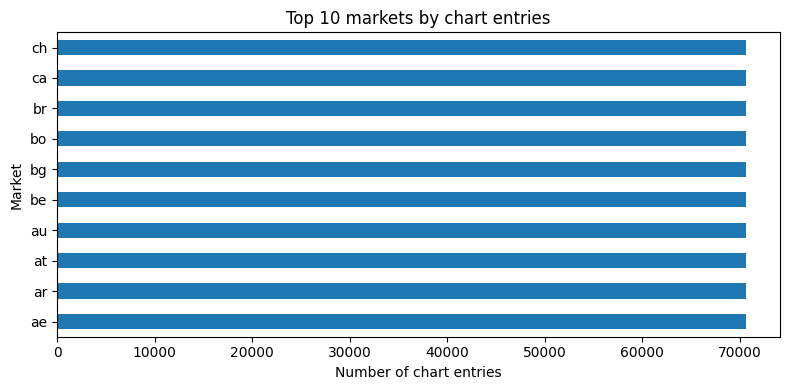

In [5]:
if "country" in df:
    top = df["country"].fillna("Unknown").value_counts().head(10)
    ax = top.sort_values().plot.barh(figsize=(8, 4), title="Top 10 markets by chart entries")
    ax.set_xlabel("Number of chart entries")
    ax.set_ylabel("Market")
    plt.tight_layout()
    plt.show()
else:
    print("Market chart unavailable: country column missing.")

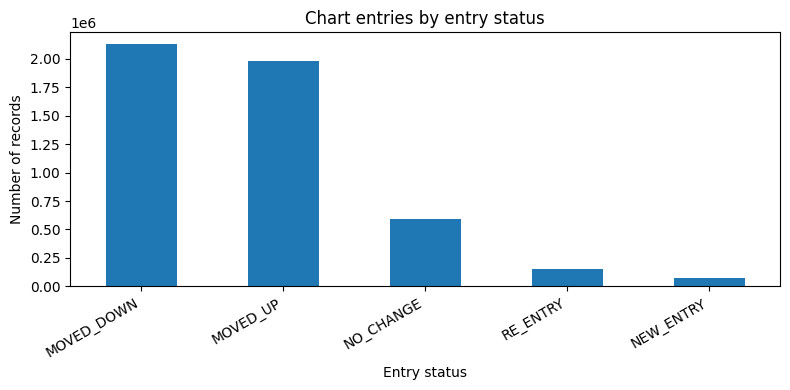

In [6]:
if "entry_status" in df:
    counts = df["entry_status"].fillna("Unknown").value_counts().head(8)
    ax = counts.plot.bar(figsize=(8, 4), title="Chart entries by entry status")
    ax.set_xlabel("Entry status")
    ax.set_ylabel("Number of records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Status chart unavailable: entry_status column missing.")

---

## 6. What the findings mean

Use the outputs above to complete this short interpretation after each refresh.

- **Coverage:** How many records and unique entities appear? Which dates or markets are represented?
- **Data quality:** Which fields are missing? Are repeated business keys present?
- **Main pattern:** Which markets or statuses dominate, or how are listener counts distributed?
- **Limitation:** Repeated chart entries, unknown metrics, and source coverage affect interpretation.

**Next step:** Apply cleaning rules separately in `etl/cleaning/`. This EDA notebook does not alter or load MySQL tables.